In [1]:
words = open('names.txt', 'r').read().splitlines()

In [2]:
import torch

N = torch.zeros((27,27), dtype=torch.int32)


In [3]:
chars = sorted(list(set(''.join(words))))
stoi = {s:i+1 for i,s in enumerate(chars)}
stoi['.'] = 0
itos = {i:s for s,i in stoi.items()}

In [4]:
N[0]

for w in words:
    #add '.' before and after each word
    chs = ['.'] + list(w) + ['.']
    for ch1, ch2 in zip(chs, chs[1:]): #for all the character combinations
        #get the coordinate of the character combo via stoi
        ix1 = stoi[ch1]
        ix2 = stoi[ch2]
        N[ix1, ix2] += 1     #incriment N at that coordinate


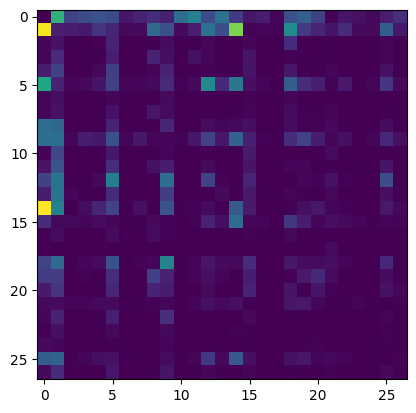

In [5]:
import matplotlib.pyplot as plt
%matplotlib inline
plt.imshow(N)

In [20]:
P = (N+1).float() #adding 1 makes sure there are no 0 probabilities in dataset ~ aka model smoothing
P /= P.sum(1, keepdim=True)

In [21]:
g = torch.Generator().manual_seed(2147483647)

for i in range(5):
    ix = 0
    out = []
    while True:
        p=P[ix]
        ix = torch.multinomial(p, num_samples=1, replacement=True, generator=g).item()
        out.append(itos[ix])
        if ix == 0:
            break
    print(''.join(out))

cexze.
momasurailezitynn.
konimittain.
llayn.
ka.


In [24]:
#evaluate the quality of the model

log_likelihood = 0.0
n = 0

for w in words:
    #add '.' before and after each word
    chs = ['.'] + list(w) + ['.']
    for ch1, ch2 in zip(chs, chs[1:]): #for all the character combinations
        #get the coordinate of the character combo via stoi
        ix1 = stoi[ch1]
        ix2 = stoi[ch2]
        prob = P[ix1, ix2]
        logprob = torch.log(prob)
        log_likelihood += logprob
        n += 1
        #print(f'{ch1}{ch2}:  {prob:.4f}  {logprob:.4f}')
print(f'{log_likelihood=}')
nll = -log_likelihood
print(f'{nll=}')
print(f'{nll/n=}')

log_likelihood=tensor(-559951.5625)
nll=tensor(559951.5625)
nll/n=tensor(2.4544)


In [107]:
#create the data set of all the bigrams

xs, ys = [], []

for w in words:
    chs = ['.'] + list(w) + ['.']
    for ch1, ch2 in zip(chs, chs[1:]): #for all the character combinations
        ix1 = stoi[ch1]
        ix2 = stoi[ch2]
        xs.append(ix1)
        ys.append(ix2)

xs = torch.tensor(xs)
ys = torch.tensor(ys)
num = xs.nelement()
print(num)

228146


In [101]:
#one hot encoding
import torch.nn.functional as F
xenc = F.one_hot(xs, num_classes=27).float()

In [102]:
#initialize weights
g = torch.Generator().manual_seed(2147483647)
W = torch.randn((27, 27), generator=g, requires_grad=True)

In [111]:
#for k iterations
for k in range(100):
    #forward pass through dataset
    logits = xenc @ W #log-counts
    counts = logits.exp() 
    probs = counts / counts.sum(1, keepdims=True) #average exp is softmax
    loss = -probs[torch.arange(num), ys].log().mean() #probabilities nn assigned to the next correct character
    
    #backward pass
    W.grad = None #set gradients to zero
    loss.backward()
    
    #update weights
    W.data += -50*W.grad
    print(loss.item())

2.4706592559814453
2.470482110977173
2.470308542251587
2.4701380729675293
2.469970941543579
2.4698073863983154
2.469646692276001
2.469489336013794
2.469334602355957
2.4691832065582275
2.469034194946289
2.4688878059387207
2.4687447547912598
2.46860408782959
2.468465566635132
2.468329668045044
2.4681966304779053
2.4680657386779785
2.4679369926452637
2.4678103923797607
2.467686176300049
2.467564105987549
2.4674441814422607
2.4673259258270264
2.467209815979004
2.4670956134796143
2.4669833183288574
2.4668731689453125
2.466764450073242
2.466657876968384
2.466552734375
2.466449022293091
2.4663474559783936
2.4662468433380127
2.4661483764648438
2.4660513401031494
2.465955972671509
2.4658613204956055
2.465768814086914
2.465677499771118
2.465587615966797
2.46549916267395
2.46541166305542
2.4653255939483643
2.465240716934204
2.4651575088500977
2.4650752544403076
2.464993715286255
2.464913845062256
2.4648349285125732
2.464757204055786
2.4646804332733154
2.4646048545837402
2.4645304679870605
2.46445

In [112]:
#sample

g = torch.Generator().manual_seed(2147483647)
for i in range(5):
    out = []
    ix = 0
    while True:
        xenc = F.one_hot(torch.tensor([ix]), num_classes=27).float()
        logits = xenc @ W # predict log-counts
        counts = logits.exp()
        p = counts / counts.sum(1, keepdims=True)

        ix = torch.multinomial(p, num_samples=1, replacement=True, generator=g).item()
        out.append(itos[ix])
        if ix == 0:
            break
    print(''.join(out))

cexze.
momasurailezityha.
konimittain.
llayn.
ka.
